[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch10-mini_workbook.ipynb)

# Byte-pair encoding on five words

The corpus has five word types: `low` 5 times, `lower` 2, `new` 6, `newer` 3,
`wider` 2. Each word is spelled in characters and closed with the end-of-word
marker `</w>`. In byte-pair encoding, the adjacent pair with the highest count
is merged into one symbol and the counts are taken again. Which pair is merged
first, and which counts fall after it?

In [1]:
#@title Setup: run this cell first
from collections import Counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# The five-word corpus of the ch10 lecture, section 10.2.1 of the chapter: invented numbers.
CORPUS = {"low": 5, "lower": 2, "new": 6, "newer": 3, "wider": 2}
END = "</w>"
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 9})


def spell(corpus):  # each word as a tuple of its characters and the end-of-word marker
    return {tuple(w) + (END,): n for w, n in corpus.items()}


def pair_counts(rows):  # each adjacent pair with its count over all copies of the words
    c = Counter()
    for symbols, n in rows.items():
        for pair in zip(symbols, symbols[1:]):
            c[pair] += n
    return c


def symbol_counts(rows):  # each symbol with its count over all copies of the words
    c = Counter()
    for symbols, n in rows.items():
        for s in symbols:
            c[s] += n
    return c


def merge(rows, pair):  # every adjacent occurrence of the pair written as one symbol
    out = {}
    for symbols, n in rows.items():
        new, i = [], 0
        while i < len(symbols):
            if symbols[i:i + 2] == pair:
                new.append(pair[0] + pair[1])
                i += 2
            else:
                new.append(symbols[i])
                i += 1
        out[tuple(new)] = n
    return out


def best(counts):  # the pair with the highest count; a tie goes to the first in alphabetical order
    return max(sorted(counts), key=counts.get)


def length(rows):  # the length of the corpus in symbols
    return sum(len(s) * n for s, n in rows.items())


def label(pair):
    return f"({pair[0]}, {pair[1]})"


def count_bars(counts, title):  # one bar per pair, the highest count first and in red
    order = sorted(counts, key=lambda p: (-counts[p], p))
    fig, ax = plt.subplots(figsize=(5.2, 0.28 * len(order) + 1), layout="constrained")
    bars = ax.barh([label(p) for p in order], [counts[p] for p in order],
                   color=["#a6192e" if p == best(counts) else "#9e9e9e" for p in order])
    ax.bar_label(bars, fontsize=9)
    ax.invert_yaxis()
    ax.set(xlabel="count", title=title)
    plt.show()


def merge_bars(before, after, pair):  # the count of each pair before and after the merge
    names = sorted(set(before) | set(after), key=lambda p: (-before[p], -after[p], p))
    y = list(range(len(names)))
    fig, ax = plt.subplots(figsize=(5.6, 0.3 * len(names) + 1), layout="constrained")
    ax.barh([i - 0.2 for i in y], [before[p] for p in names], 0.4, color="#9e9e9e", label="before")
    ax.barh([i + 0.2 for i in y], [after[p] for p in names], 0.4, color="#a6192e", label="after")
    ax.set(yticks=y, yticklabels=[label(p) for p in names], xlabel="count", title="merged: " + label(pair))
    ax.invert_yaxis()
    ax.legend(fontsize=8)
    plt.show()


def run_merges(k):  # k merges of the corpus: the words after them, one row per merge, the base size
    rows, log = spell(CORPUS), []
    base = len(symbol_counts(rows))
    for m in range(1, k + 1):
        counts = pair_counts(rows)
        pair = best(counts)
        rows = merge(rows, pair)
        log.append((m, pair, counts[pair], base + m, length(rows)))
    return rows, log, base


def merge_report(k):  # the merge table, the words after it, corpus length and vocabulary size per merge
    rows, log, base = run_merges(k)
    for m, pair, c, v, n in log:
        print(f"merge {m:2d}: {label(pair):20s} count {c:2d}, vocabulary {v:2d}, corpus {n:2d} symbols")
    print("words:", " | ".join(" ".join(s) for s in rows))
    fig, ax = plt.subplots(figsize=(5.2, 2.8), layout="constrained")
    ax.plot([0] + [r[0] for r in log], [length(spell(CORPUS))] + [r[4] for r in log], "o-", color="#a6192e", label="corpus length")
    ax.plot([0] + [r[0] for r in log], [base] + [r[3] for r in log], "s-", color="#9e9e9e", label="vocabulary size")
    ax.set(xlabel="merges", ylabel="symbols", ylim=(0, None))
    ax.legend(fontsize=8)
    plt.show()


def wordpiece(pair):  # the joint count of the pair over the product of its symbols' separate counts
    rows = spell(CORPUS)
    s = symbol_counts(rows)
    return pair_counts(rows)[pair] / (s[pair[0]] * s[pair[1]])


def rank_panels(pairs):  # left, the count of each pair; right, its WordPiece score
    joint = pair_counts(spell(CORPUS))
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.2), layout="constrained")
    for ax, values, title, form in zip(axes, ([joint[p] for p in pairs], [wordpiece(p) for p in pairs]),
                                       ("count", "WordPiece score"), ("{:d}", "{:.4f}")):
        bars = ax.bar([label(p) for p in pairs], values, color=["#9e9e9e", "#a6192e"])
        ax.bar_label(bars, labels=[form.format(v) for v in values], fontsize=9)
        ax.set(title=title, ylim=(0, max(values) * 1.2))
    plt.show()

## 1. Pair counts

The count of an adjacent pair grows by 1 for each place the pair occurs in each
copy of a word. Run the cell: which pair has the highest count? Then set `WORDS`
to `["low", "lower"]` and run it again: what is the count of `(l, o)`?

highest: (w, </w>) 11


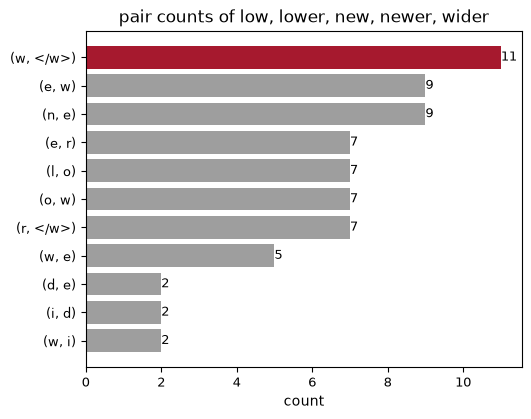

In [2]:
WORDS = ["low", "lower", "new", "newer", "wider"]
counts = pair_counts(spell({w: CORPUS[w] for w in WORDS}))
print("highest:", label(best(counts)), counts[best(counts)])
count_bars(counts, "pair counts of " + ", ".join(WORDS))

### Solution

In [3]:
counts = pair_counts(spell(CORPUS))
two = pair_counts(spell({w: CORPUS[w] for w in ["low", "lower"]}))
top = best(counts)
display(Markdown(f"`{label(top)}` has the highest count, {counts[top]}: `low` ends in `w` {CORPUS['low']} times and "
                 f"`new` {CORPUS['new']} times. With `low` and `lower` alone, `(l, o)` has the count {two[('l', 'o')]}, "
                 f"{CORPUS['low']} + {CORPUS['lower']}."))

`(w, </w>)` has the highest count, 11: `low` ends in `w` 5 times and `new` 6 times. With `low` and `lower` alone, `(l, o)` has the count 7, 5 + 2.

## 2. The first merge

After a merge, every adjacent occurrence of the pair is one symbol, and that
symbol has new neighbours. In the chart, grey bars are the counts before the
merge and red bars the counts after it. Run the cell: which pair has the highest
count after the merge, and of the other pairs, which count falls most? Then set
`PAIR` to `("n", "e")` and run it again: which words change?

highest after the merge: (n, e) 9


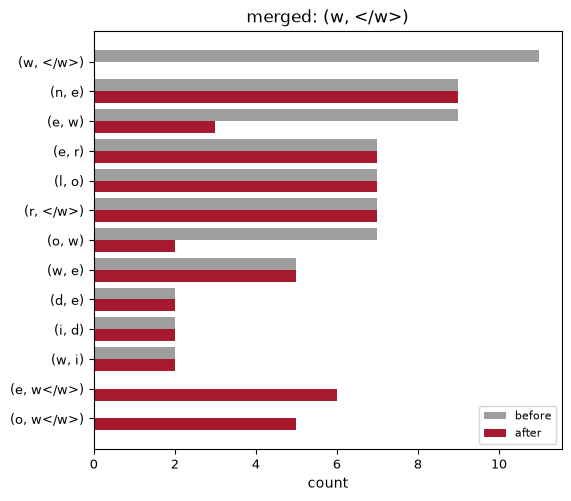

In [4]:
PAIR = ("w", END)
rows = spell(CORPUS)
before, after = pair_counts(rows), pair_counts(merge(rows, PAIR))
print("highest after the merge:", label(best(after)), after[best(after)])
merge_bars(before, after, PAIR)

### Solution

In [5]:
first = ("w", END)
rows = spell(CORPUS)
b, a = pair_counts(rows), pair_counts(merge(rows, first))
fall = max(sorted(p for p in b if p != first), key=lambda p: b[p] - a[p])
changed = ["".join(s).replace(END, "") for s in rows if merge({s: 1}, ("n", "e")) != {s: 1}]
display(Markdown(f"After the merge, `{label(best(a))}` has the highest count, {a[best(a)]}. Of the other pairs, "
                 f"`{label(fall)}` falls most, from {b[fall]} to {a[fall]}: in `new` the `w` now belongs to `w{END}`. "
                 f"`(o, w)` falls from {b[('o', 'w')]} to {a[('o', 'w')]}. A merge of `(n, e)` changes `{changed[0]}` and `{changed[1]}`."))

After the merge, `(n, e)` has the highest count, 9. Of the other pairs, `(e, w)` falls most, from 9 to 3: in `new` the `w` now belongs to `w</w>`. `(o, w)` falls from 7 to 2. A merge of `(n, e)` changes `new` and `newer`.

## 3. Merges, vocabulary, corpus length

The vocabulary starts with the base symbols, the characters with the marker, and
each merge adds one symbol. A tie goes to the pair first in alphabetical order.
Run the cell with `MERGES` at `5`: how many entries has the vocabulary, and how
many symbols has the corpus? Then set `MERGES` to `11` and run it again: which
words are a single symbol?

merge  1: (w, </w>)            count 11, vocabulary 10, corpus 75 symbols
merge  2: (n, e)               count  9, vocabulary 11, corpus 66 symbols
merge  3: (e, r)               count  7, vocabulary 12, corpus 59 symbols
merge  4: (er, </w>)           count  7, vocabulary 13, corpus 52 symbols
merge  5: (l, o)               count  7, vocabulary 14, corpus 45 symbols
words: lo w</w> | lo w er</w> | ne w</w> | ne w er</w> | w i d er</w>


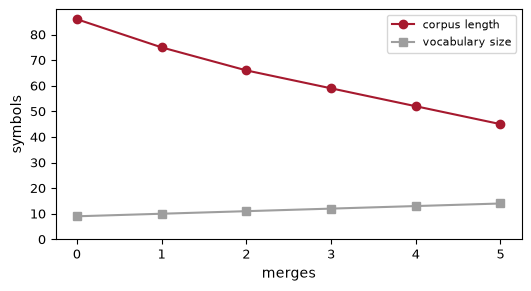

In [6]:
MERGES = 5
merge_report(MERGES)

### Solution

In [7]:
_, five, base = run_merges(5)
rows, eleven, _ = run_merges(11)
whole = ["".join(s).replace(END, "") for s in rows if len(s) == 1]
display(Markdown(f"After {five[-1][0]} merges the vocabulary has {five[-1][3]} entries, {base} base symbols and one per "
                 f"merge, and the corpus has {five[-1][4]} symbols, down from {length(spell(CORPUS))}. After "
                 f"{eleven[-1][0]} merges the vocabulary has {eleven[-1][3]} entries and the corpus {eleven[-1][4]} symbols; "
                 f"{', '.join('`' + w + '`' for w in whole)} are single symbols."))

After 5 merges the vocabulary has 14 entries, 9 base symbols and one per merge, and the corpus has 45 symbols, down from 86. After 11 merges the vocabulary has 20 entries and the corpus 22 symbols; `low`, `new`, `newer` are single symbols.

## Appendix. The WordPiece score of a pair

Under WordPiece, pairs are ordered by a score: the joint count of the pair over
the product of the separate counts of its symbols. A pair whose symbols occur
only together has a high score, however rare it is. The left panel has the counts
of `(e, r)` and `(i, d)`, the right panel their scores.

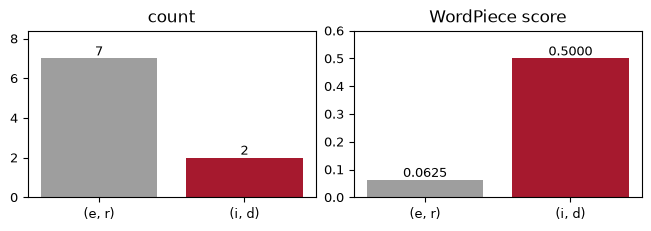

In [8]:
rank_panels([("e", "r"), ("i", "d")])

**Exercise.** Set `PAIR` to `("w", "e")`. What is its score, and does it lie
above the score of `(e, r)`?

In [9]:
PAIR = ("e", "r")
print(label(PAIR), f"WordPiece score: {wordpiece(PAIR):.4f}")

(e, r) WordPiece score: 0.0625


### Solution

In [10]:
c, s = pair_counts(spell(CORPUS)), symbol_counts(spell(CORPUS))
display(Markdown(f"`(w, e)` has the score {c[('w', 'e')]} / ({s['w']} × {s['e']}) = {wordpiece(('w', 'e')):.4f}, below "
                 f"{wordpiece(('e', 'r')):.4f} for `(e, r)`. Under WordPiece `(i, d)` goes first, at {wordpiece(('i', 'd')):.2f}, "
                 "although under byte-pair encoding its count is among the lowest."))

`(w, e)` has the score 5 / (18 × 16) = 0.0174, below 0.0625 for `(e, r)`. Under WordPiece `(i, d)` goes first, at 0.50, although under byte-pair encoding its count is among the lowest.